In [1]:

!pip install -q -U ultralytics roboflow pandas matplotlib seaborn scikit-learn

import torch
import ultralytics

print("Ultralytics version:", ultralytics.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not enabled. Enable GPU in Colab Runtime settings.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 8.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 74.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 34.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 126.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 126.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 123.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 141.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the so

In [2]:
%pip install -q -U ultralytics roboflow matplotlib seaborn scikit-learn
%pip install -q pandas==2.2.3

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 77.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 117.1 MB/s eta 0:00:00


In [1]:
import torch
import pandas as pd
import ultralytics

print("Ultralytics:", ultralytics.__version__)
print("Pandas:", pd.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Ultralytics: 8.4.183
Pandas: 2.2.3
GPU available: True
GPU: Tesla T4


In [2]:
from getpass import getpass
from roboflow import Roboflow
from pathlib import Path

# Enter your Roboflow API key securely
API_KEY = getpass("Enter your Roboflow API key: ")

# Your existing Roboflow project details
WORKSPACE = "sreemals-workspace"
PROJECT = "fish-detection-classification-2-vghzd"
VERSION = 4

# Connect to Roboflow
rf = Roboflow(api_key=API_KEY)
project = rf.workspace(WORKSPACE).project(PROJECT)

# Download dataset
dataset = project.version(VERSION).download("yolov8")

# Get data.yaml path
DATA_YAML = str(Path(dataset.location) / "data.yaml")

print("Dataset location:", dataset.location)
print("Dataset YAML:", DATA_YAML)
print(Path(DATA_YAML).read_text())

Enter your Roboflow API key: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to fish-detection-classification-2-4 in yolov8:: 100%|██████████| 2885/2885 [00:00<00:00, 7170.83it/s]

Dataset location: /content/fish-detection-classification-2-4
Dataset YAML: /content/fish-detection-classification-2-4/data.yaml
names:
- Alagoduwa_Spoiled
- Alagoduwa_Very_fresh
- Alagoduwa_fresh
nc: 3
roboflow:
  license: CC BY 4.0
  project: fish-detection-classification-2-vghzd
  url: https://universe.roboflow.com/sreemals-workspace/fish-detection-classification-2-vghzd/dataset/4
  version: 4
  workspace: sreemals-workspace
test: ../test/images
train: ../train/images
val: ../valid/images



In [3]:

import yaml
from pathlib import Path

with open(DATA_YAML, "r") as f:
    data_config = yaml.safe_load(f)

print("Classes:", data_config["names"])
print("Number of classes:", data_config["nc"])

assert data_config["nc"] == 3, "Expected exactly 3 classes"
assert len(data_config["names"]) == 3, "Check class names"

for split in ["train", "val", "test"]:
    split_path = data_config.get(split)

    if split_path is None:
        print(f"WARNING: '{split}' split missing in data.yaml")
        continue

    p = Path(split_path)
    if not p.is_absolute():
        p = Path(data_config.get("path", dataset.location)) / p

    print(split, "->", p, "| exists:", p.exists())


Classes: ['Alagoduwa_Spoiled', 'Alagoduwa_Very_fresh', 'Alagoduwa_fresh']
Number of classes: 3
train -> /content/fish-detection-classification-2-4/../train/images | exists: False
val -> /content/fish-detection-classification-2-4/../valid/images | exists: False
test -> /content/fish-detection-classification-2-4/../test/images | exists: False


In [4]:
from pathlib import Path
import yaml

print("Dataset location:", dataset.location)
print("DATA_YAML:", DATA_YAML)

root = Path(dataset.location)
print("\nDataset folders:")

for folder in ["train", "valid", "test"]:
    images = root / folder / "images"
    print(f"{folder}: {images} | exists: {images.exists()}")

print("\nCurrent data.yaml:")
print(Path(DATA_YAML).read_text())

Dataset location: /content/fish-detection-classification-2-4
DATA_YAML: /content/fish-detection-classification-2-4/data.yaml

Dataset folders:
train: /content/fish-detection-classification-2-4/train/images | exists: True
valid: /content/fish-detection-classification-2-4/valid/images | exists: True
test: /content/fish-detection-classification-2-4/test/images | exists: True

Current data.yaml:
names:
- Alagoduwa_Spoiled
- Alagoduwa_Very_fresh
- Alagoduwa_fresh
nc: 3
roboflow:
  license: CC BY 4.0
  project: fish-detection-classification-2-vghzd
  url: https://universe.roboflow.com/sreemals-workspace/fish-detection-classification-2-vghzd/dataset/4
  version: 4
  workspace: sreemals-workspace
test: ../test/images
train: ../train/images
val: ../valid/images



In [5]:
from pathlib import Path
import yaml

root = Path(dataset.location).resolve()
DATA_YAML = str(root / "data.yaml")

with open(DATA_YAML, "r") as f:
    data_config = yaml.safe_load(f)

# Correct dataset paths
data_config["path"] = str(root)
data_config["train"] = "train/images"
data_config["val"] = "valid/images"
data_config["test"] = "test/images"

# Save the corrected configuration
with open(DATA_YAML, "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

# Verify all splits
for split in ["train", "val", "test"]:
    folder = root / data_config[split]
    count = len(list(folder.glob("*")))
    print(f"{split}: {folder}")
    print(f"Exists: {folder.exists()} | Files: {count}\n")

print("Corrected YAML:", DATA_YAML)

train: /content/fish-detection-classification-2-4/train/images
Exists: True | Files: 1260

val: /content/fish-detection-classification-2-4/valid/images
Exists: True | Files: 120

test: /content/fish-detection-classification-2-4/test/images
Exists: True | Files: 60

Corrected YAML: /content/fish-detection-classification-2-4/data.yaml


In [6]:
from ultralytics import YOLO
import torch
import pandas as pd
from pathlib import Path

# Check GPU availability
if not torch.cuda.is_available():
    raise RuntimeError("Enable a GPU in Colab before training.")

print("GPU:", torch.cuda.get_device_name(0))

# Models to compare
MODELS = {
    "YOLOv8s": "yolov8s.pt",
    "YOLO11s": "yolo11s.pt",
    "YOLO26s": "yolo26s.pt",
}

EPOCHS = 100
IMAGE_SIZE = 640
BATCH_SIZE = 16

RUNS_DIR = "/content/fish-detection-classification-2-4"
trained_models = {}

for model_name, weights in MODELS.items():

    print(f"\n{'=' * 50}")
    print("Training:", model_name)
    print(f"{'=' * 50}")

    model = YOLO(weights)

    model.train(
        data=DATA_YAML,
        epochs=EPOCHS,
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        patience=20,
        seed=42,
        deterministic=True,
        workers=2,
        device=0,
        project=RUNS_DIR,
        name=model_name,
        exist_ok=True,
        plots=True,
        save=True,

        # Disable additional online augmentation
        hsv_h=0.0,
        hsv_s=0.0,
        hsv_v=0.0,
        degrees=0.0,
        translate=0.0,
        scale=0.0,
        fliplr=0.0,
        flipud=0.0,
        mosaic=0.0,
        mixup=0.0,
        copy_paste=0.0,
    )

    best_path = (
        Path(RUNS_DIR)
        / model_name
        / "weights"
        / "best.pt"
    )

    if not best_path.exists():
        raise FileNotFoundError(
            f"Best weights not found: {best_path}"
        )

    trained_models[model_name] = str(best_path)

    print("Best model saved:", best_path)

print("\nAll models trained successfully!")
print("\nTrained models:")
for name, path in trained_models.items():
    print(f"{name}: {path}")

GPU: Tesla T4

Training: YOLOv8s
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fish-detection-classification-2-4/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=YOLOv

In [7]:

from ultralytics import YOLO
from pathlib import Path
import pandas as pd
import yaml

with open(DATA_YAML, "r") as f:
    cfg = yaml.safe_load(f)

if "test" not in cfg:
    raise ValueError("No test split found in data.yaml. Create a test split first.")

EVAL_DIR = "/content/fish_freshness_evaluation"
summary = []
class_rows = []

for model_name, weights_path in trained_models.items():
    print("\nEvaluating:", model_name)

    model = YOLO(weights_path)

    metrics = model.val(
        data=DATA_YAML,
        split="test",
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        device=0,
        plots=True,
        project=EVAL_DIR,
        name=model_name,
        exist_ok=True,
        verbose=True
    )

    speed = metrics.speed
    total_ms = (
        speed.get("preprocess", 0)
        + speed.get("inference", 0)
        + speed.get("postprocess", 0)
    )

    summary.append({
        "Model": model_name,
        "Precision": float(metrics.box.mp),
        "Recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50),
        "mAP50-95": float(metrics.box.map),
        "Preprocess_ms": speed.get("preprocess", 0),
        "Inference_ms": speed.get("inference", 0),
        "Postprocess_ms": speed.get("postprocess", 0),
        "Approx_FPS": 1000 / total_ms if total_ms > 0 else None,
        "Weights": weights_path
    })

    # Per-class detection metrics
    box_metrics = metrics.box
    names = model.names

    for j, class_id in enumerate(box_metrics.ap_class_index):
        class_id = int(class_id)

        class_rows.append({
            "Model": model_name,
            "Class": names[class_id],
            "Precision": float(box_metrics.p[j]),
            "Recall": float(box_metrics.r[j]),
            "F1": float(box_metrics.f1[j]),
            "AP50": float(box_metrics.ap50[j]),
            "AP50-95": float(box_metrics.ap[j]),
        })

summary_df = pd.DataFrame(summary)
class_df = pd.DataFrame(class_rows)

display(summary_df.round(4))
display(class_df.round(4))

summary_df.to_csv("/content/model_comparison.csv", index=False)
class_df.to_csv("/content/class_wise_metrics.csv", index=False)



Evaluating: YOLOv8s
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 16.2±8.0 MB/s, size: 37.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/fish-detection-classification-2-4/test/labels... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 461.9it/s 0.1s
val: New cache created: /content/fish-detection-classification-2-4/test/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 59, len(boxes) = 61. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP

,Model,Precision,Recall,mAP50,mAP50-95,Preprocess_ms,Inference_ms,Postprocess_ms,Approx_FPS,Weights
0,YOLOv8s,0.9450,0.8997,0.9729,0.8775,8.0999,15.1577,4.9602,35.4386,/content/fish-detection-classification-2-4/YOL...
1,YOLO11s,0.9920,0.9180,0.9771,0.8858,8.3109,13.0893,2.5641,41.7287,/content/fish-detection-classification-2-4/YOL...
2,YOLO26s,0.9966,0.9814,0.9817,0.8951,8.0618,13.7145,3.7413,39.1886,/content/fish-detection-classification-2-4/YOL...


,Model,Class,Precision,Recall,F1,AP50,AP50-95
0,YOLOv8s,Alagoduwa_Spoiled,1.0000,0.8729,0.9322,0.9950,0.8859
1,YOLOv8s,Alagoduwa_Very_fresh,0.9489,0.8261,0.8833,0.9312,0.8572
2,YOLOv8s,Alagoduwa_fresh,0.8861,1.0000,0.9396,0.9926,0.8895
3,YOLO11s,Alagoduwa_Spoiled,0.9912,1.0000,0.9956,0.9950,0.9337
4,YOLO11s,Alagoduwa_Very_fresh,1.0000,0.8041,0.8914,0.9459,0.8904
5,YOLO11s,Alagoduwa_fresh,0.9848,0.9500,0.9671,0.9905,0.8332
6,YOLO26s,Alagoduwa_Spoiled,0.9994,1.0000,0.9997,0.9950,0.9124
7,YOLO26s,Alagoduwa_Very_fresh,0.9905,0.9565,0.9732,0.9550,0.8904
8,YOLO26s,Alagoduwa_fresh,1.0000,0.9878,0.9938,0.9950,0.8826


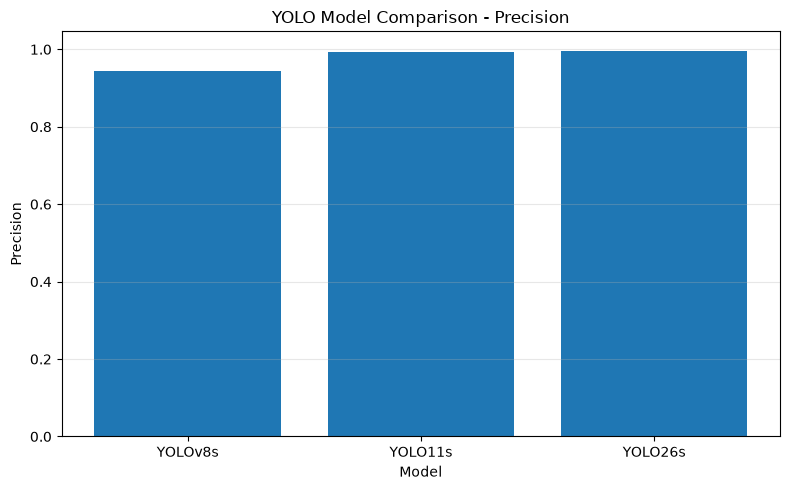

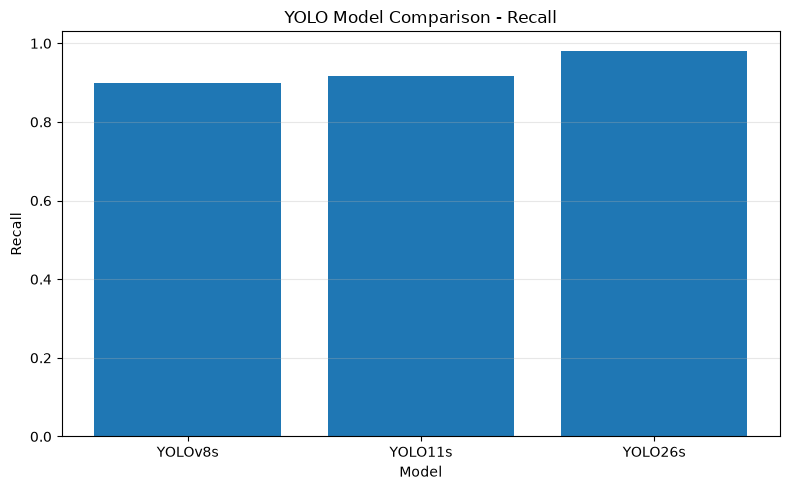

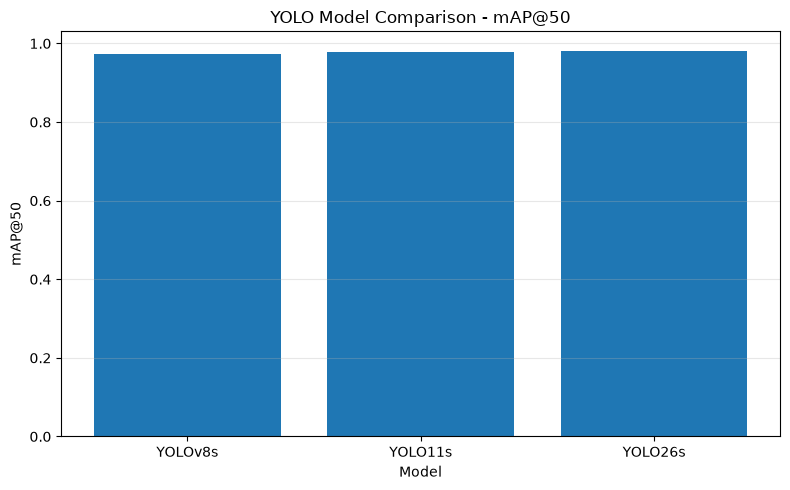

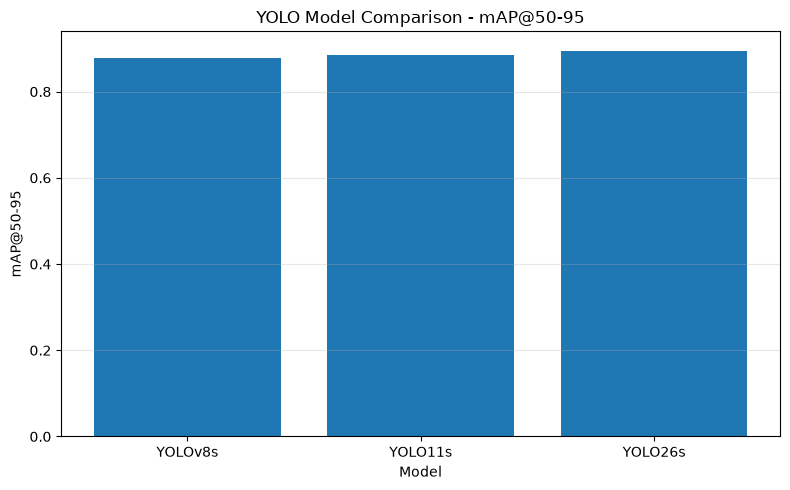

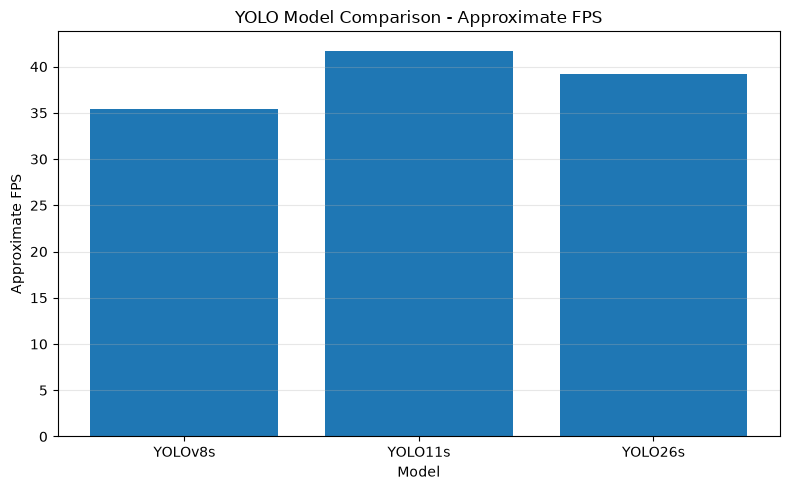

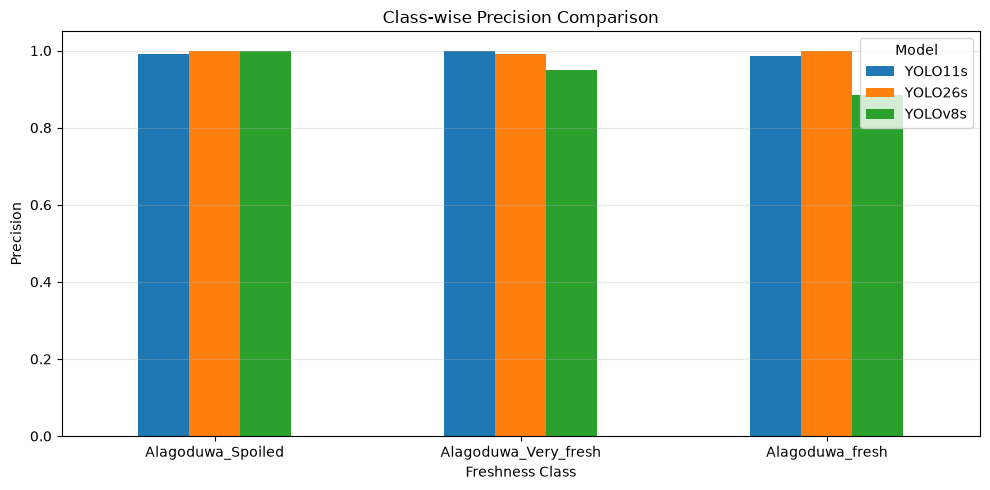

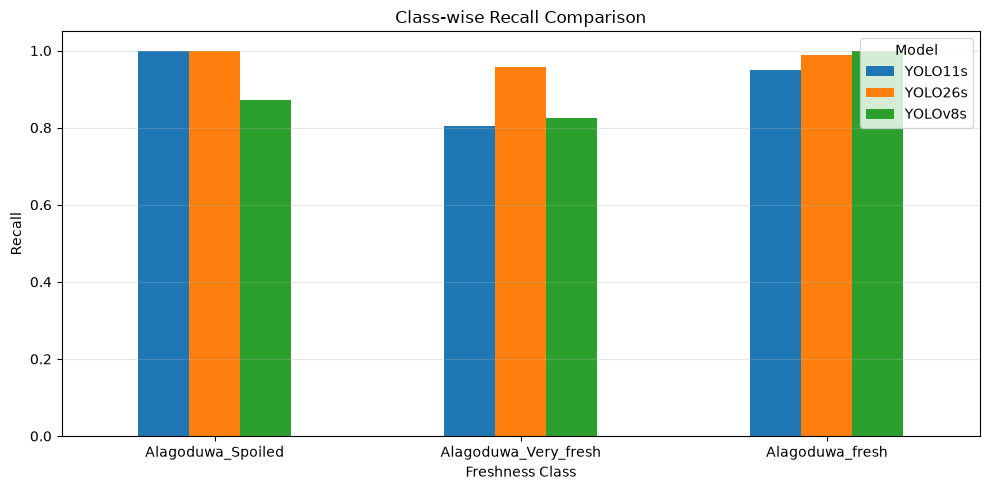

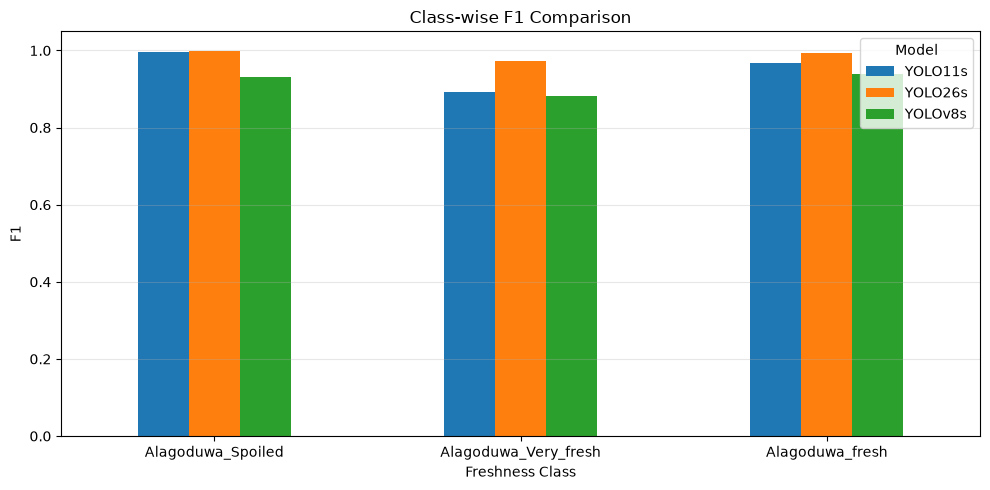

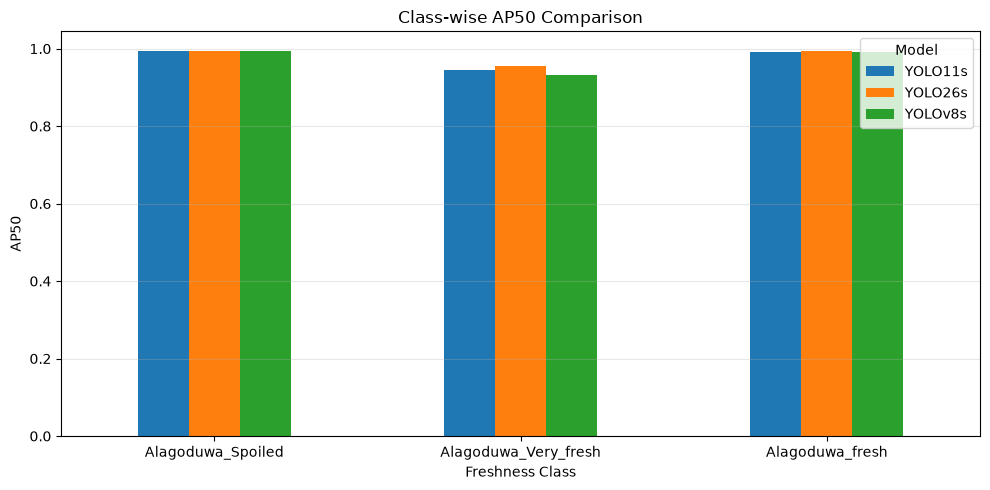

In [8]:

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

df = pd.read_csv("/content/model_comparison.csv")

metrics_to_plot = [
    ("Precision", "Precision"),
    ("Recall", "Recall"),
    ("mAP50", "mAP@50"),
    ("mAP50-95", "mAP@50-95"),
    ("Approx_FPS", "Approximate FPS"),
]

for column, title in metrics_to_plot:
    plt.figure(figsize=(8, 5))
    plt.bar(df["Model"], df[column])
    plt.title(f"YOLO Model Comparison - {title}")
    plt.ylabel(title)
    plt.xlabel("Model")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"/content/{column}_comparison.png", dpi=200)
    plt.show()

# Compare freshness classes
class_df = pd.read_csv("/content/class_wise_metrics.csv")

for metric in ["Precision", "Recall", "F1", "AP50"]:
    pivot = class_df.pivot(
        index="Class",
        columns="Model",
        values=metric
    )

    ax = pivot.plot(kind="bar", figsize=(10, 5))
    ax.set_title(f"Class-wise {metric} Comparison")
    ax.set_ylabel(metric)
    ax.set_xlabel("Freshness Class")
    ax.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(f"/content/classwise_{metric}.png", dpi=200)
    plt.show()


In [9]:

from pathlib import Path
from IPython.display import display, Image

eval_root = Path("/content/fish_freshness_evaluation")

for model_name in MODELS:
    model_dir = eval_root / model_name

    print(f"\n{'='*40}\n{model_name}\n{'='*40}")

    if not model_dir.exists():
        print("Evaluation folder not found:", model_dir)
        continue

    for pattern in [
        "confusion_matrix.png",
        "confusion_matrix_normalized.png",
        "BoxPR_curve.png",
        "BoxF1_curve.png",
        "BoxP_curve.png",
        "BoxR_curve.png",
    ]:
        for img_path in model_dir.rglob(pattern):
            print(img_path.name)
            display(Image(filename=str(img_path)))


Output hidden; open in https://colab.research.google.com to view.


Training history: YOLOv8s


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
68,69,1154.06,0.07848,0.08621,0.82179,0.87300,0.95084,0.95969,0.87736,0.39430,0.52020,1.04754,0.000467,0.000467,0.000467
69,70,1170.71,0.07116,0.08056,0.81991,0.90648,0.94234,0.96091,0.89145,0.38946,0.44539,1.05152,0.000453,0.000453,0.000453
70,71,1187.29,0.06821,0.07816,0.81952,0.88109,0.92452,0.95901,0.88809,0.39855,0.52512,1.06874,0.000439,0.000439,0.000439


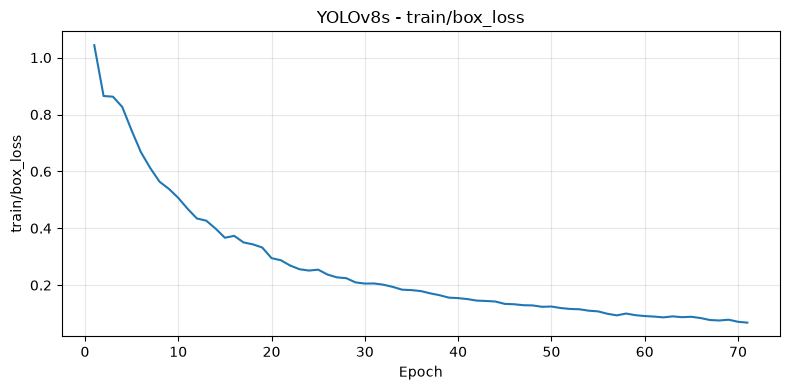

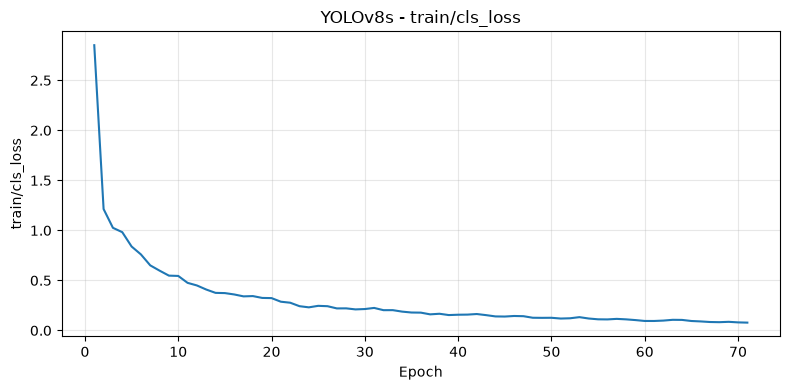

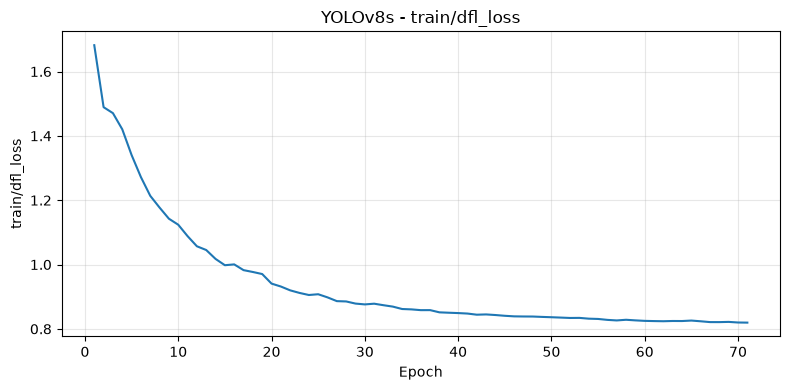

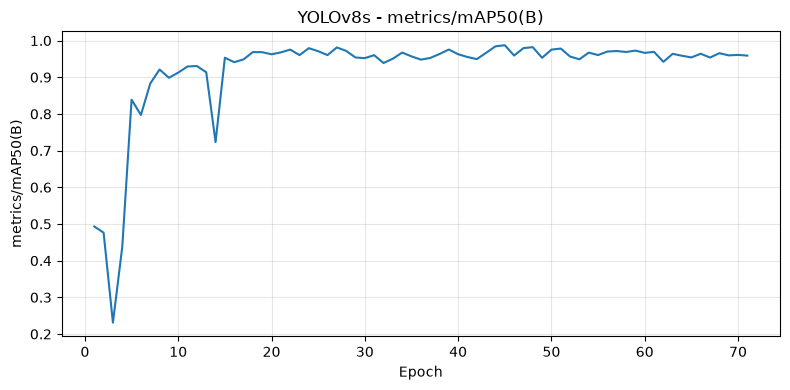

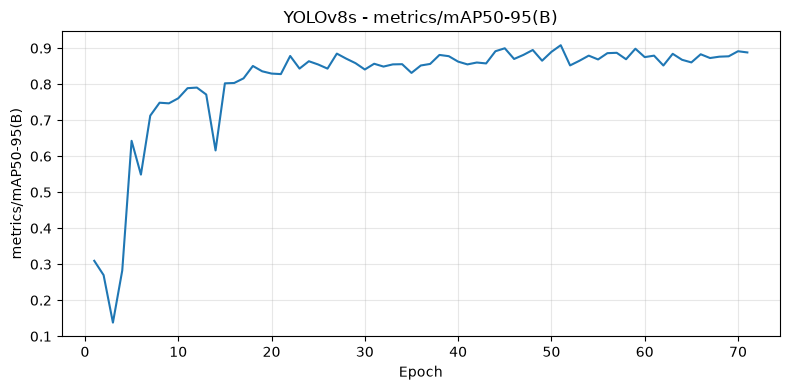

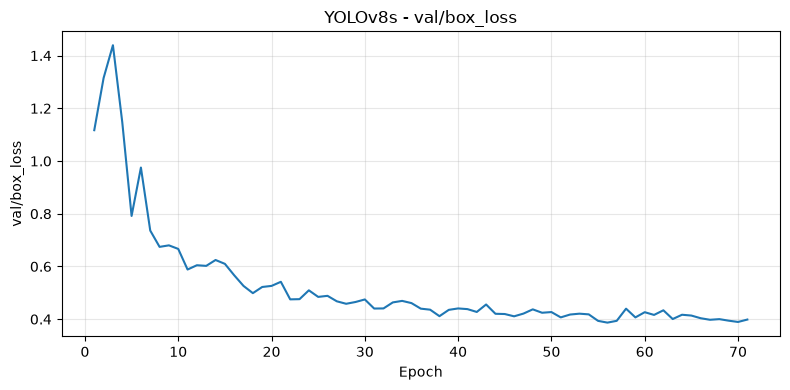

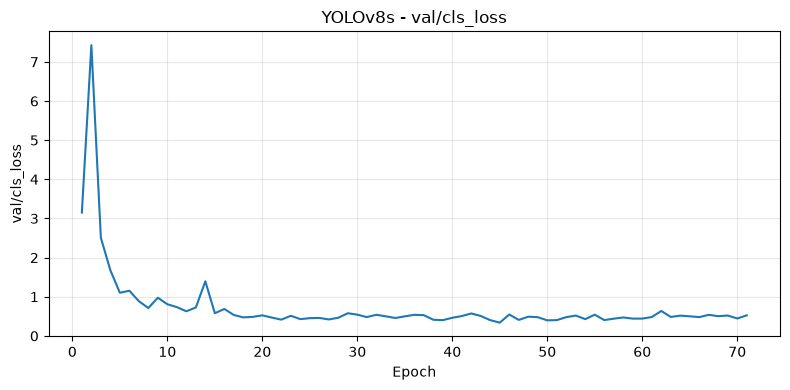

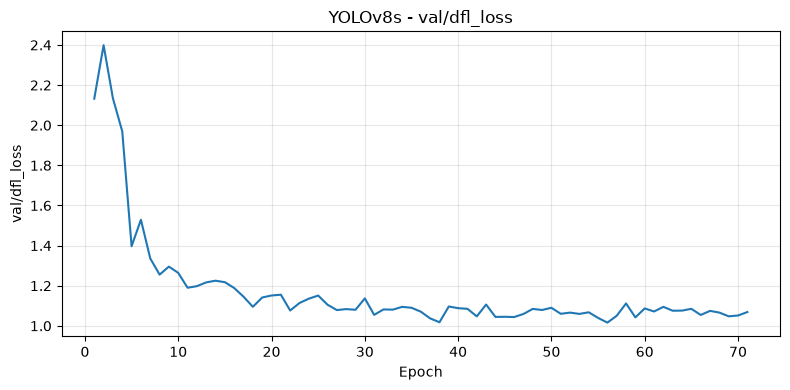


Training history: YOLO11s


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
66,67,1168.45,0.08307,0.08637,0.82428,0.93866,0.96578,0.98799,0.90623,0.40740,0.33399,1.09674,0.000495,0.000495,0.000495
67,68,1185.85,0.08467,0.08868,0.82450,0.95804,0.94991,0.97391,0.89674,0.39743,0.35672,1.07463,0.000481,0.000481,0.000481
68,69,1203.36,0.08682,0.09449,0.82454,0.93218,0.91118,0.96409,0.88467,0.38988,0.44431,1.06348,0.000467,0.000467,0.000467


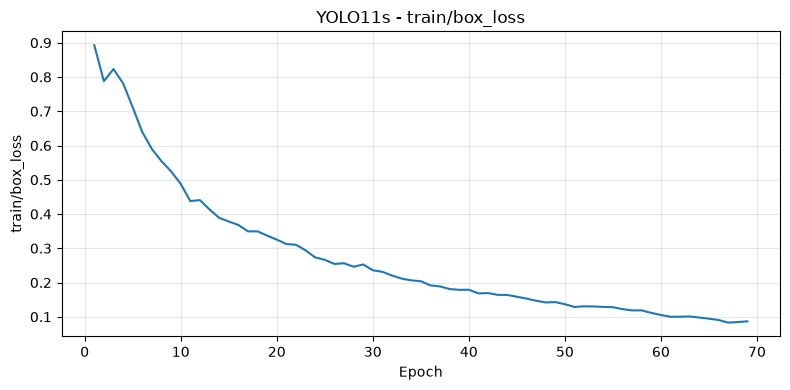

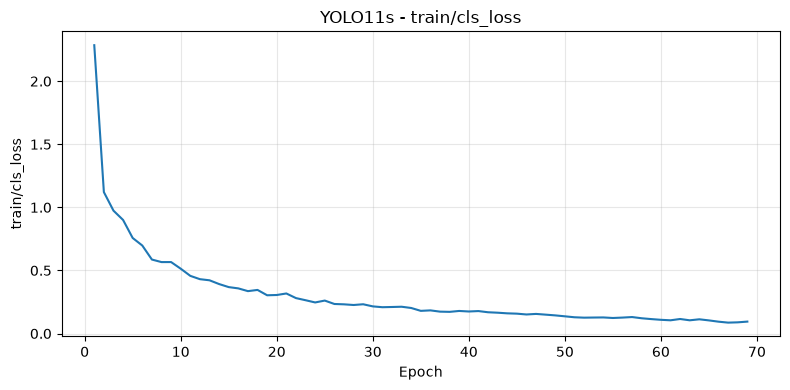

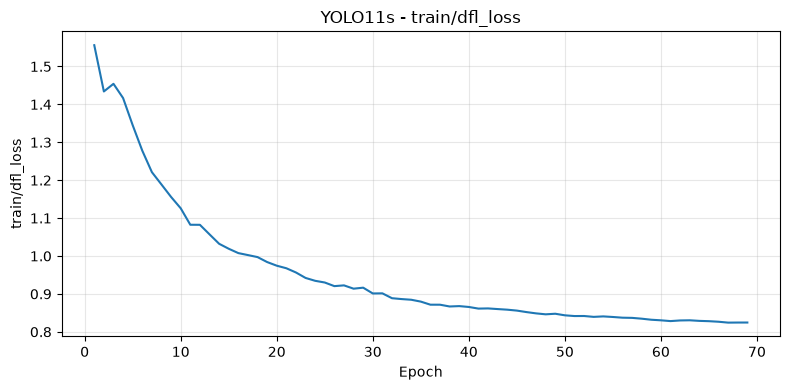

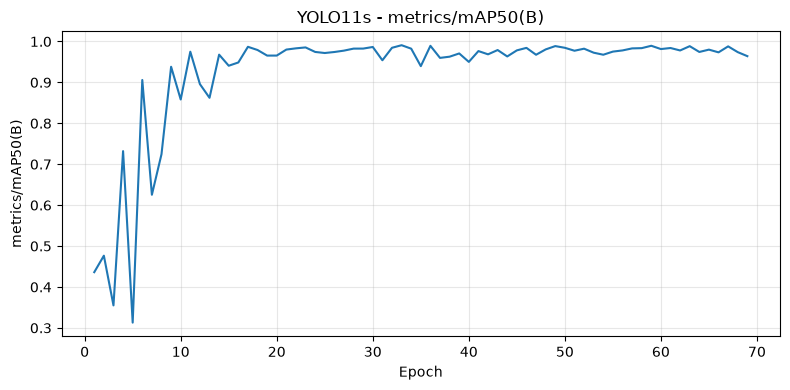

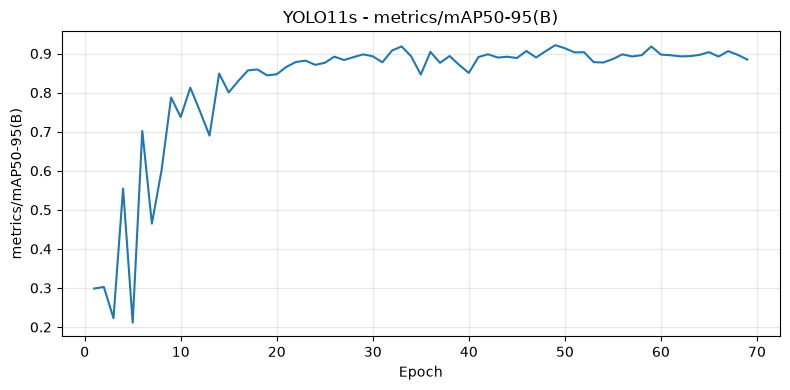

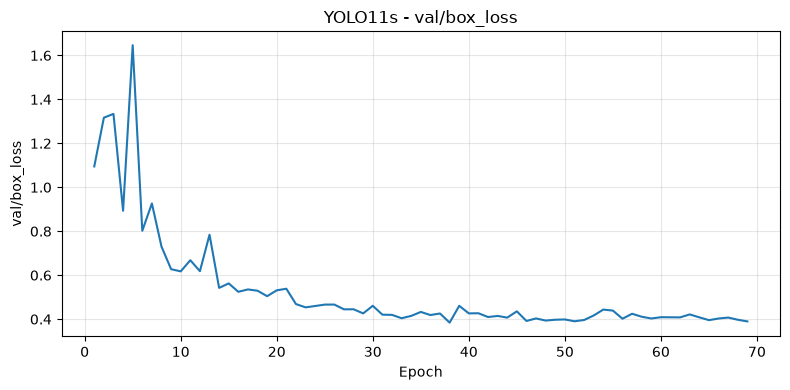

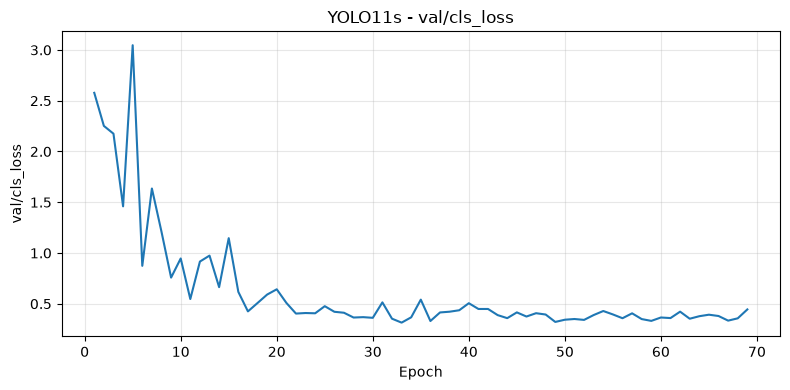

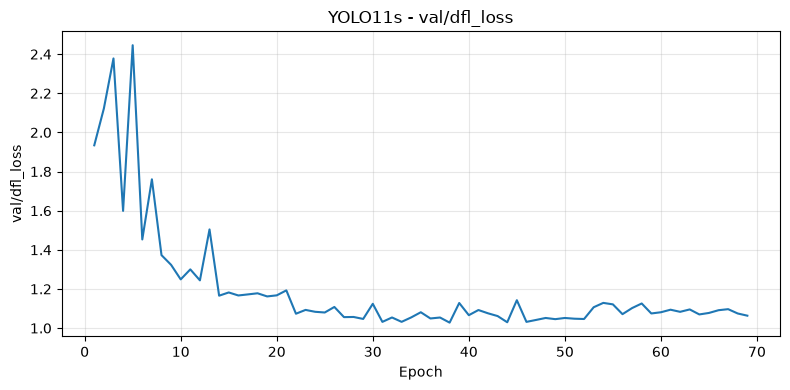


Training history: YOLO26s


,epoch,time,train/box_loss,train/cls_loss,train/l1_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/l1_loss,lr/pg0,lr/pg1,lr/pg2
76,77,1625.08,0.10208,0.06073,0.00362,0.97554,0.97672,0.99379,0.90181,0.49288,0.25524,0.01978,0.000354,0.000354,0.000354
77,78,1645.98,0.11757,0.07097,0.00416,0.96778,0.97773,0.99413,0.89917,0.50348,0.24939,0.02024,0.000340,0.000340,0.000340
78,79,1666.94,0.12012,0.06209,0.00422,0.96708,0.98004,0.99413,0.89771,0.50063,0.24408,0.02011,0.000326,0.000326,0.000326


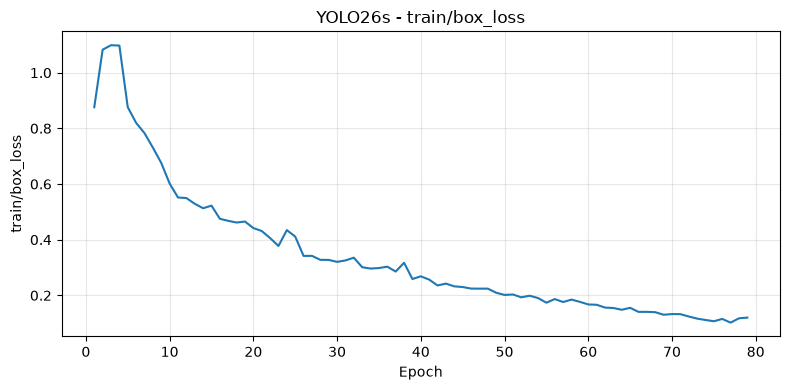

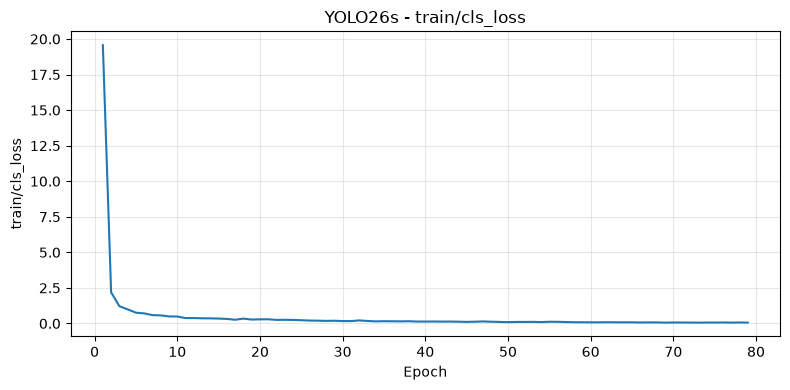

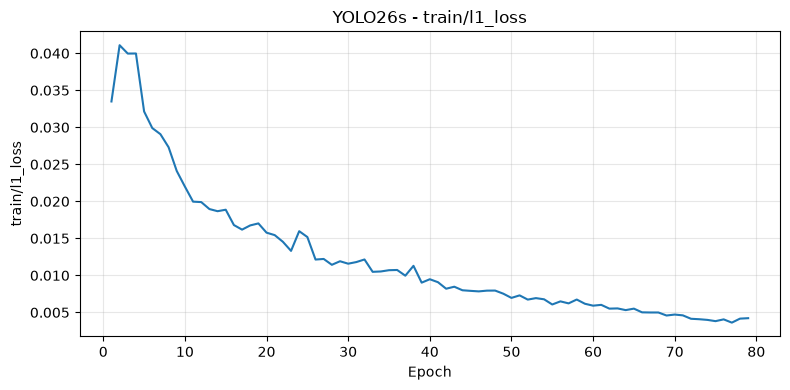

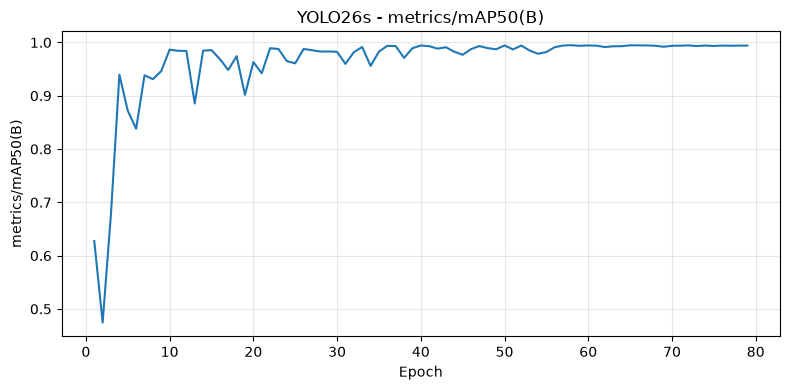

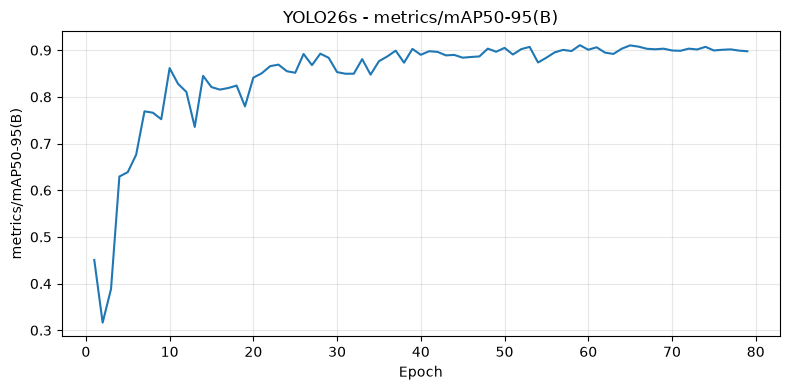

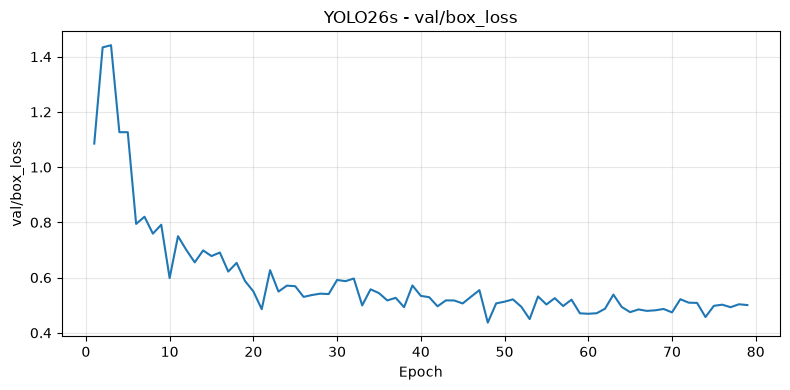

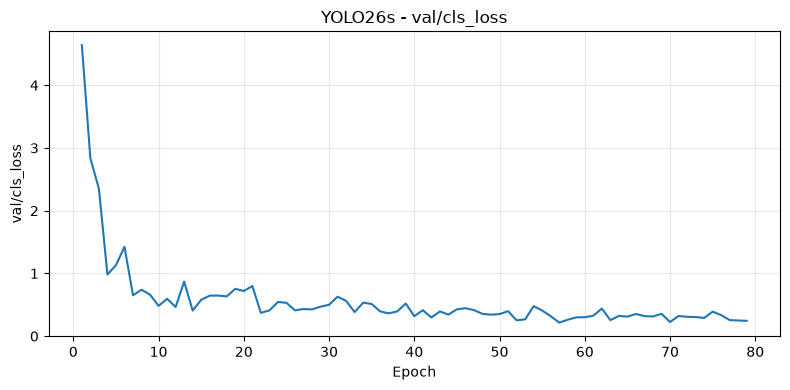

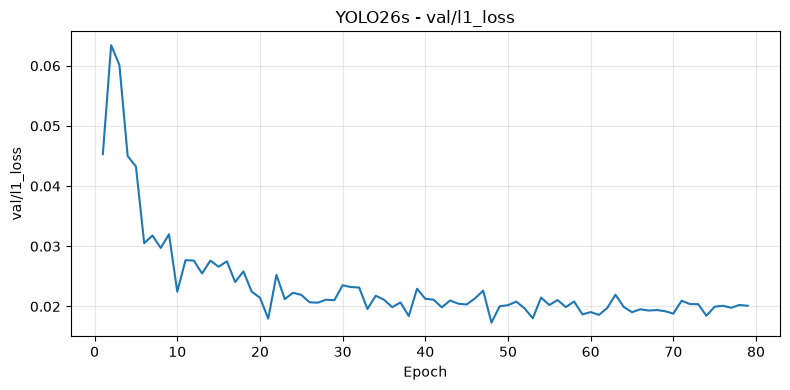

In [10]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

for model_name in MODELS:
    csv_path = (
        Path(RUNS_DIR) / model_name / "results.csv"
    )

    if not csv_path.exists():
        print("Missing results:", csv_path)
        continue

    history = pd.read_csv(csv_path)
    history.columns = history.columns.str.strip()

    print("\nTraining history:", model_name)
    display(history.tail(3))

    for col in history.columns:
        if "loss" in col.lower() or "map50" in col.lower():
            plt.figure(figsize=(8, 4))
            plt.plot(history.index + 1, history[col])
            plt.title(f"{model_name} - {col}")
            plt.xlabel("Epoch")
            plt.ylabel(col)
            plt.grid(alpha=0.3)
            plt.tight_layout()
            plt.show()


In [11]:

import shutil
from pathlib import Path
from google.colab import files

output_dir = Path("/content/fish_research_results")
output_dir.mkdir(exist_ok=True)

# Copy metric tables
for name in [
    "model_comparison.csv",
    "class_wise_metrics.csv",
]:
    src = Path("/content") / name
    if src.exists():
        shutil.copy2(src, output_dir / name)

# Copy comparison charts
for src in Path("/content").glob("*.png"):
    shutil.copy2(src, output_dir / src.name)

# Copy model evaluation plots and training histories
for folder in [
    Path(EVAL_DIR),
    Path(RUNS_DIR),
]:
    if folder.exists():
        shutil.copytree(
            folder,
            output_dir / folder.name,
            dirs_exist_ok=True
        )

# Include trained model weights
weights_dir = output_dir / "weights"
weights_dir.mkdir(exist_ok=True)

for model_name, weights_path in trained_models.items():
    shutil.copy2(
        weights_path,
        weights_dir / f"{model_name}_best.pt"
    )

zip_path = shutil.make_archive(
    "/content/fish_research_results",
    "zip",
    root_dir=output_dir
)

print("Results package created:", zip_path)
files.download(zip_path)


Results package created: /content/fish_research_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>